# 21. Combined map (fusion of the best methods)

Pixel-wise max of several anomaly maps, each normalised with fixed good_cal statistics of this fabric (`F.fit_fusion` + `F.fuse`), never per-tile min-max. **Edit `FUSE` to the best 2-3 methods from the comparison in README section 8.**

Method: `filters.py` (`METHOD_NAME = "combined"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/combined/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "combined"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = False       # F.fuse already divides each map by the tile's own level before combining
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
FUSE = {                  # best 2-3 methods from README section 8 (edit after comparing)
    "background_subtraction": lambda t: F.background_subtraction(t),
    "fft_notch": lambda t: F.fft_notch(t),
    "gabor_bank": lambda t: F.gabor_bank(t),
}
method = None


def fit(cal_tiles):
    """Normalisation statistics from good_cal maps only."""
    stats = F.fit_fusion({name: [fn(t) for t in cal_tiles] for name, fn in FUSE.items()})
    return lambda tile: F.fuse({name: fn(tile) for name, fn in FUSE.items()}, stats)

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 1.60   pixel threshold 1.60

                    predicted OK   predicted DAMAGED
good + hard neg.             606                  41
defect                        10                  28

false alarm rate    0.0% good_test, 8.1% hard negatives
recall              73.7%  (small <50 px: 69.6% of 23, large: 80.0% of 15)
strip level         false alarm 0.0% of 10 good strips, recall 73.7% of 38 defect strips
precision           40.6%
F1                  0.523
AUROC               0.924   (threshold-free ranking quality)
mean IoU            0.298 over all defect tiles, 0.385 over detected ones
time                74.8 ms/tile (median), fitting on good_cal 11.9 s
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\combined


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

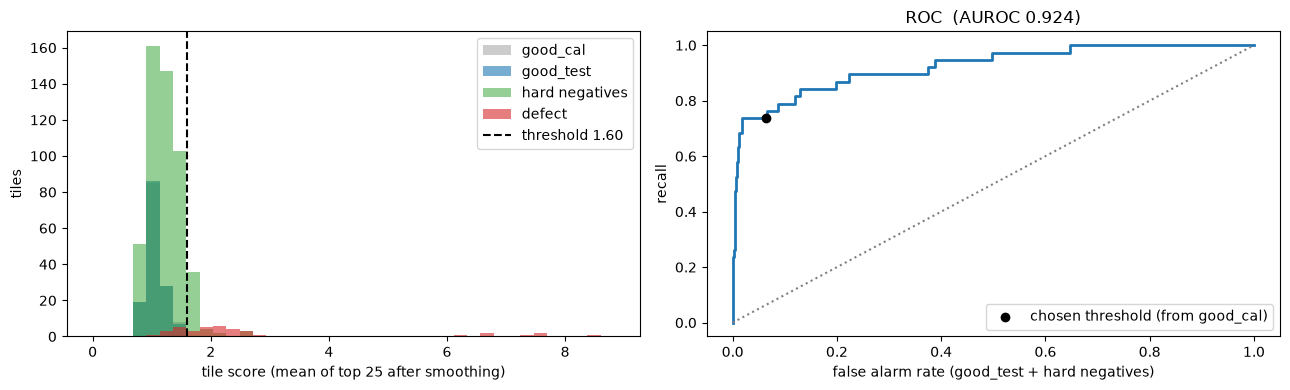

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.05          151          1.56
006          7      7     100%      0.42         1260          7.25
019         23     16      70%      0.28           15          1.88
023          3      1      33%      0.00          778          1.23
030          4      4     100%      0.46           70          2.52


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

10 missed defects, 41 false alarms


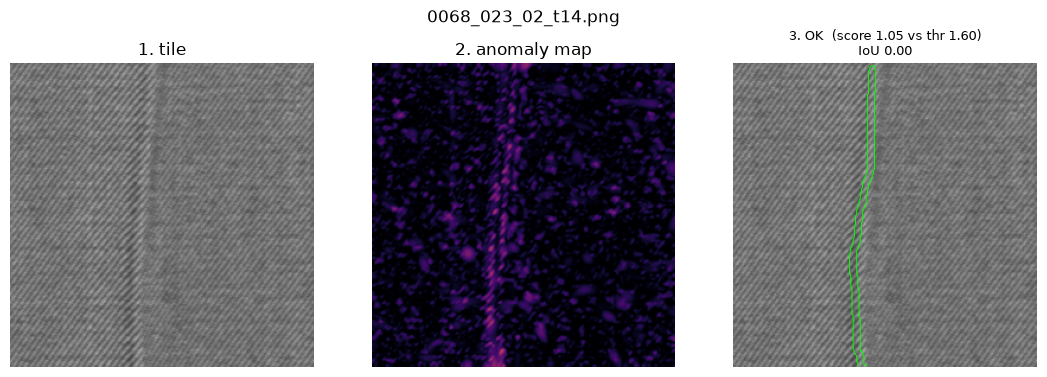

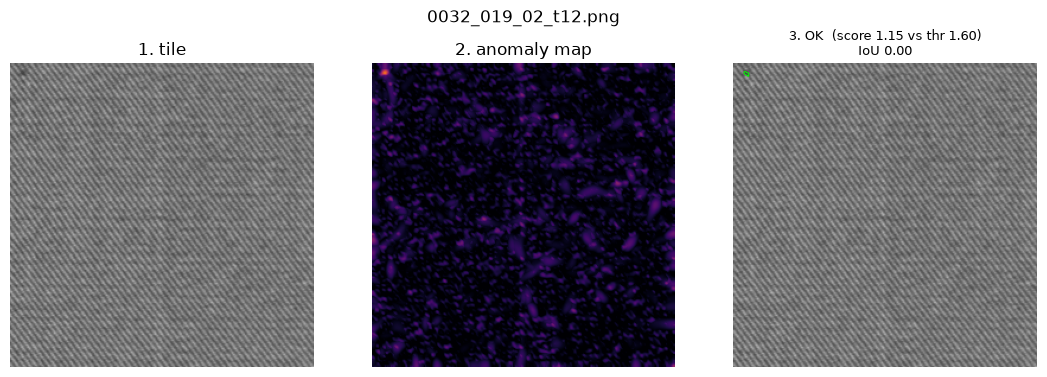

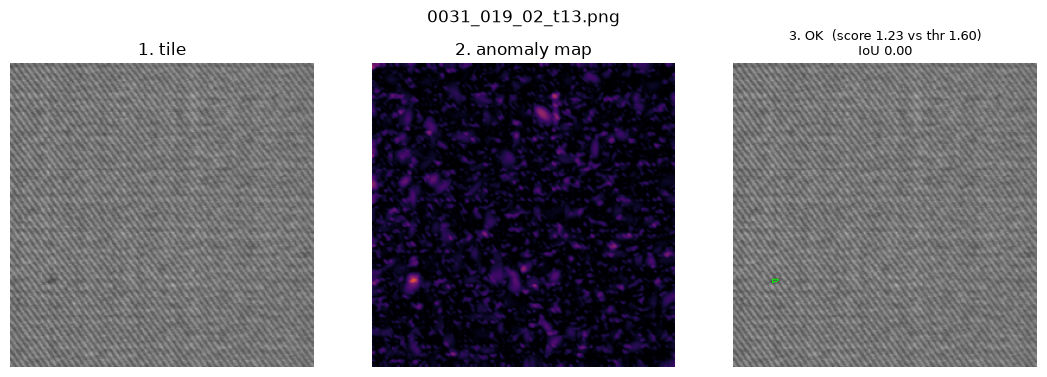

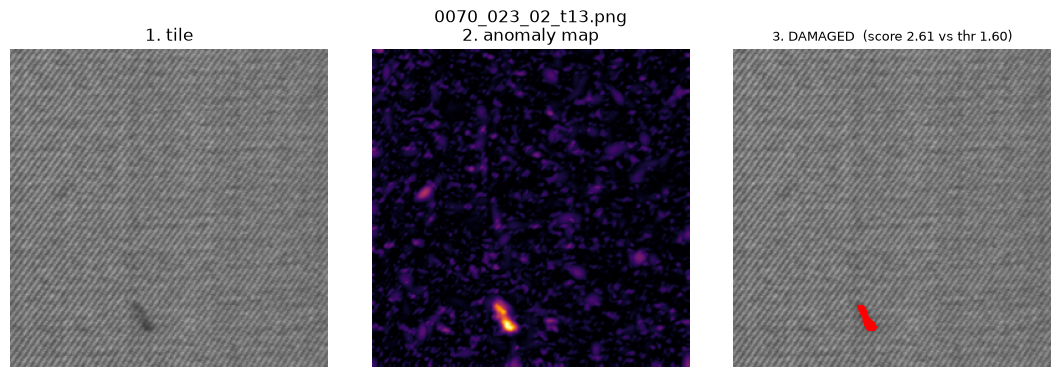

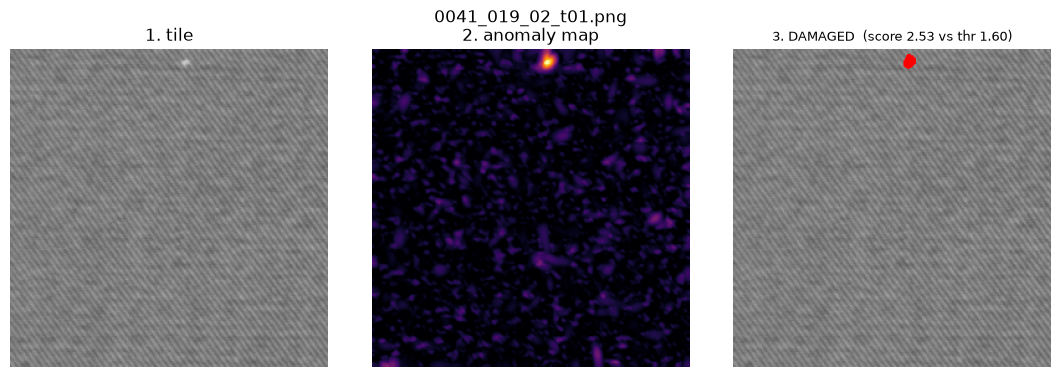

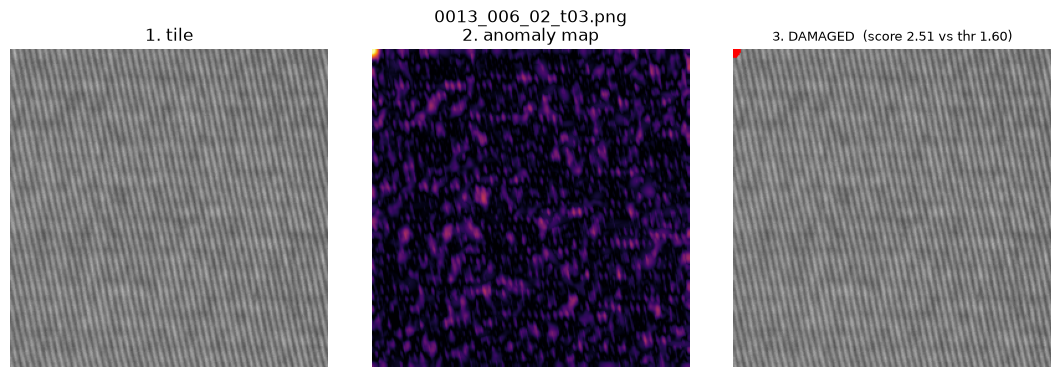

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


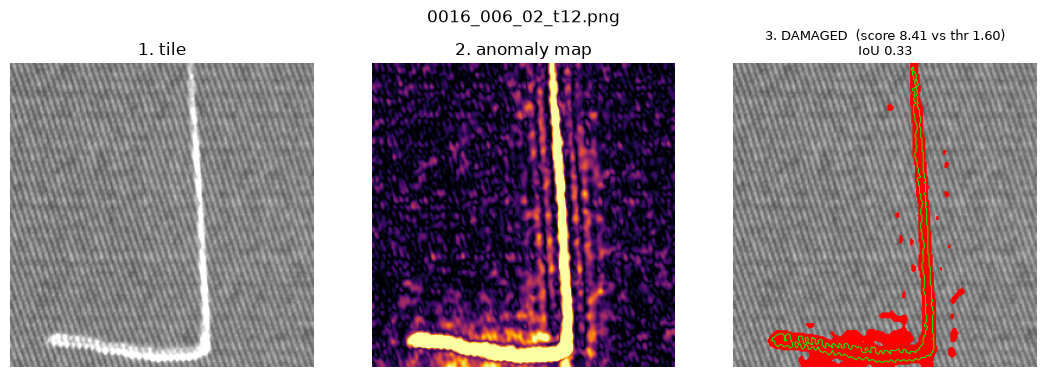

smallest defect: 0025_019_02_t10.png, 8 px


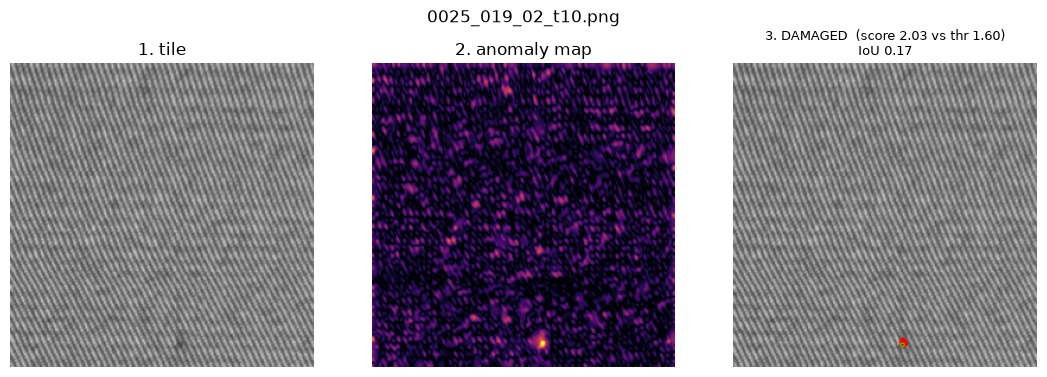

good tile: 0020_000_02_t15.png


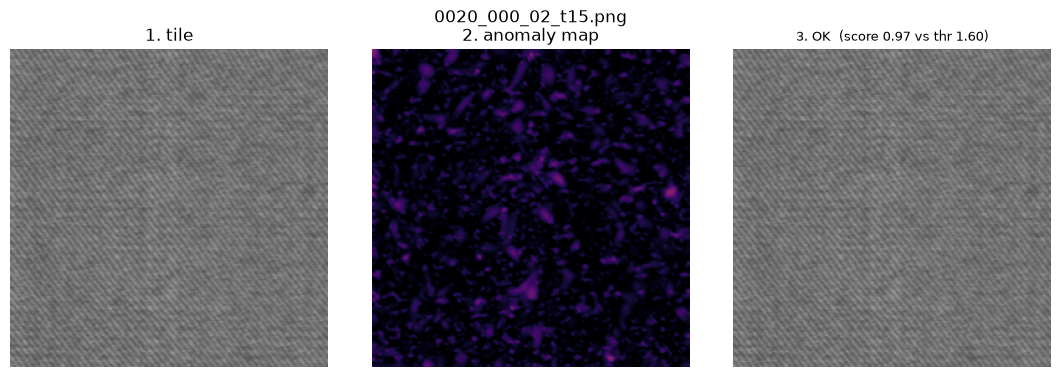

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

In [ ]:
E.show_per_type(method, fit, res, **SETTINGS)

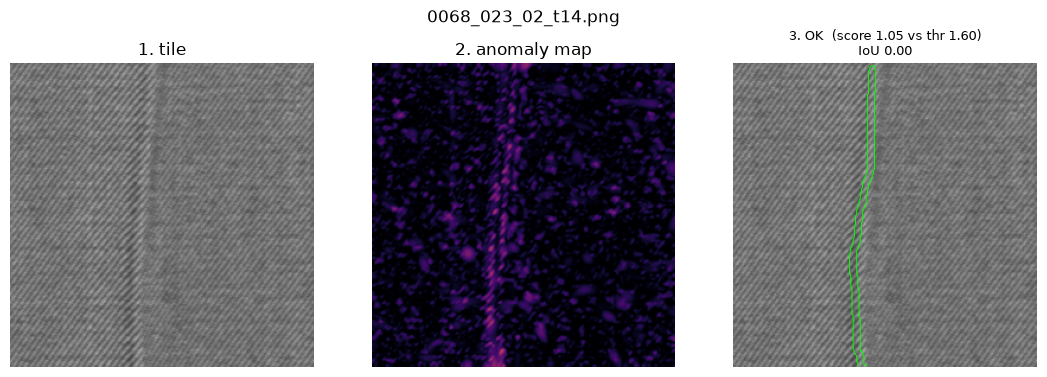

In [8]:
E.show_detection(E.OUT / "defect" / "0068_023_02_t14.png", res)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   3.6%    7.9%   66.7% 100.0%  62.5%    40.0%    71.4%  0.927  0.09  67.6
01        154   146     28   0.0%    7.5%   85.7% 100.0%  84.6%     0.0%    75.0%  0.955  0.22  68.7
02        140   507     38   0.0%    8.1%   73.7%  69.6%  80.0%     0.0%    73.7%  0.924  0.30  68.4
03        110   256     89   0.0%    5.5%   39.3%  30.8%  40.8%     0.0%    56.7%  0.760  0.04  65.1
04        138   129     12   2.9%    3.1%   66.7%  80.0%  57.1%    40.0%    70.0%  0.940  0.30  67.3
05        150    13      1   0.7%    0.0%  100.0%    n/a 100.0%    10.0%   100.0%  1.000  0.14  65.7
06        143    81      7   4.9%    9.9%   85.7%  80.0% 100.0%    40.0%   100.0%  0.948  0.09  66.0
-------------------------------------------------------------------------------------------